In [2]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [14]:
class StateBatsman(TypedDict):
    runs:int
    balls:int
    fours:int
    sixes:int

    strike_rate:float
    bpb:float
    boundry_percentage:float

In [ ]:
def calculate_strike_rate(state: StateBatsman):
    strike_rate = (state["runs"] / state["balls"]) * 100
    return {"strike_rate": strike_rate}


In [65]:
def calculate_strike_rate(state:StateBatsman)->StateBatsman:
    total_runs=state['runs']
    total_balls=state['balls']
    strike_rate=((total_runs / total_balls) * 100)
    state['strike_rate']=strike_rate
    return state

In [66]:
def calculateBallsPerBoundary(state:StateBatsman)->StateBatsman:
    boundaries = state['fours'] + state['sixes']
    if boundaries == 0:
        return 0;
    ball_per_boundry=(state['balls']/boundaries)
    state['bpb']=ball_per_boundry
    return state


In [67]:
def calculateBoundaryPercent(state:StateBatsman)->StateBatsman:
  boundaryRuns = (state['fours'] * 4) + (state['sixes'] * 6)
  boundry_percentage=((boundaryRuns / state['runs']) * 100)
  state['boundry_percentage']=boundry_percentage
  return state



In [83]:
graph=StateGraph(StateBatsman)

In [84]:
graph.add_node('calculate_strike_rate',calculate_strike_rate)
graph.add_node('calculateBallsPerBoundary',calculateBallsPerBoundary)
graph.add_node('calculateBoundaryPercent',calculateBoundaryPercent)


In [85]:
graph.add_edge(START,'calculate_strike_rate')
graph.add_edge(START,'calculateBallsPerBoundary')
graph.add_edge(START,'calculateBoundaryPercent')

graph.add_edge('calculate_strike_rate',END)
graph.add_edge('calculateBallsPerBoundary',END)
graph.add_edge('calculateBoundaryPercent',END)

In [86]:
workflow=graph.compile()

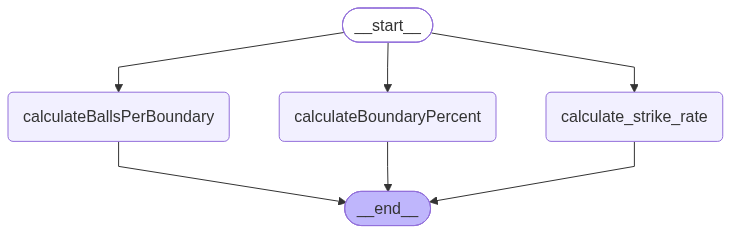

In [87]:
workflow

In [88]:
initial_state={'runs':100,'balls':20,'fours':10,'sixes':10}

In [89]:
final_State=workflow.invoke(initial_state)

In [57]:
final_State

{'runs': 100, 'balls': 20, 'fours': 10, 'sixes': 10, 'strike_rate': 500.0}

In [82]:
def calculate_strike_rate(state: StateBatsman):
    strike_rate = (state["runs"] / state["balls"]) * 100
    return {"strike_rate": strike_rate}


def calculateBallsPerBoundary(state: StateBatsman):
    boundaries = state["fours"] + state["sixes"]

    if boundaries == 0:
        return {"bpb": 0.0}

    balls_per_boundary = state["balls"] / boundaries

    return {"bpb": balls_per_boundary}


def calculateBoundaryPercent(state: StateBatsman):
    boundary_runs = (state["fours"] * 4) + (state["sixes"] * 6)

    if state["runs"] == 0:
        return {"boundry_percentage": 0.0}

    boundary_percentage = (boundary_runs / state["runs"]) * 100

    return {"boundry_percentage": boundary_percentage}